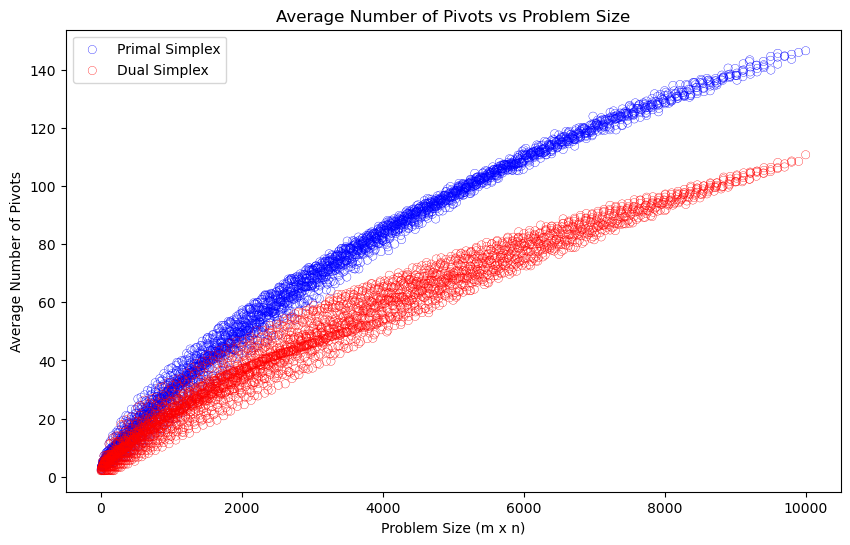

<Figure size 640x480 with 0 Axes>

In [33]:
from matplotlib import pyplot as plt
import pandas as pd

# plot average number of pivots for vs mxn (size of problem)
df_two_phase=pd.read_csv("simplex_benchmark_results_100x100.csv")
df_dual=pd.read_csv("highs-ds_benchmark_results_100x100.csv")
plt.figure(figsize=(10, 6))

average_pivots_two_phase = dict()
average_pivots_dual = dict()

for r in df_two_phase.itertuples():
    size = r.m * r.n
    time = r.average_num_pivots
    if size not in average_pivots_two_phase:
        average_pivots_two_phase[size] = []
    average_pivots_two_phase[size].append(time)

for r in df_dual.itertuples():
    size = r.m * r.n
    time = r.average_num_pivots
    if size not in average_pivots_dual:
        average_pivots_dual[size] = []
    average_pivots_dual[size].append(time)

# compute the average for each size
average_pivots_dual = {size: sum(times) / len(times) for size, times in average_pivots_dual.items()}

# compute the average for each size
average_pivots_two_phase = {size: sum(times) / len(times) for size, times in average_pivots_two_phase.items()}

# plot the results
sizes = sorted(average_pivots_two_phase.keys())
times = [average_pivots_two_phase[size] for size in sizes]
plt.scatter(sizes, times, facecolors='none', edgecolors='blue', linewidths=0.25, label='Primal Simplex')

sizes_dual = sorted(average_pivots_dual.keys())
times_dual = [average_pivots_dual[size] for size in sizes_dual]
plt.scatter(sizes_dual, times_dual, facecolors='none', edgecolors='red', linewidths=0.25, label='Dual Simplex')
plt.legend()
plt.xlabel("Problem Size (m x n)")
plt.ylabel("Average Number of Pivots")
plt.title("Average Number of Pivots vs Problem Size")

plt.show()
# save the figure
plt.savefig("problem_size.png")

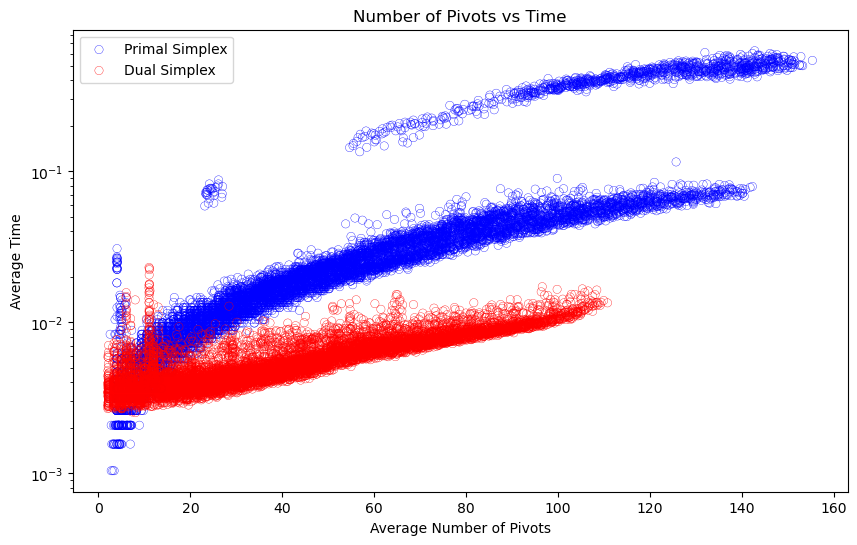

<Figure size 640x480 with 0 Axes>

In [ ]:
# plot number of pivots vs time
# use a log scale for y axis
plt.figure(figsize=(10, 6))
plt.scatter(df_two_phase["average_num_pivots"], df_two_phase["average_time"], facecolors='none', edgecolors='blue', linewidths=0.25, label='Primal Simplex')
plt.scatter(df_dual["average_num_pivots"], df_dual["average_time"], facecolors='none', edgecolors='red', linewidths=0.25, label='Dual Simplex')
plt.xlabel("Average Number of Pivots")
plt.ylabel("Average Time")
plt.yscale("log")
plt.title("Number of Pivots vs Time")
plt.legend()
plt.show()
# save the figure
plt.savefig("pivots_vs_time.png")

C:\Users\jackm\AppData\Local\Temp\ipykernel_27436\2259660585.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


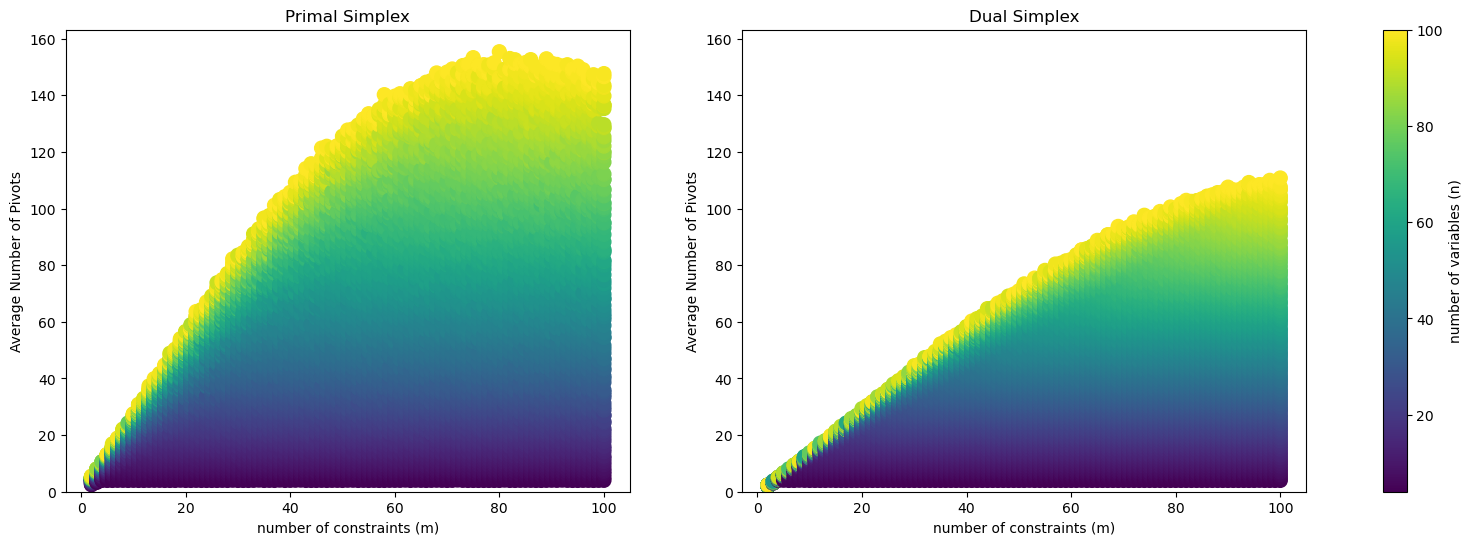

In [35]:
import matplotlib.pyplot as plt

# create two subplots and one color scale

fig, ax = plt.subplots(1, 2, figsize=(20, 6))
ax = ax.flatten()


n_values = sorted(df_two_phase["n"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

# the y axis should be the same for both plots, use the same max limit
y_max = max(df_two_phase["average_num_pivots"].max(), df_dual["average_num_pivots"].max())*1.05

for m, group in df_two_phase.groupby("m"):
    group = group.sort_values("average_num_pivots")          # largest time drawn last → on top
    ax[0].scatter(
        group["m"],
        group["average_num_pivots"],
        c=[color_map[n] for n in group["n"]],          # manual per-point colors
        s=100,
    )

#add an additional scatter plot for the dual simplex method
for m, group in df_dual.groupby("m"):
    group = group.sort_values("average_num_pivots")          # largest time drawn last → on top
    ax[1].scatter(
        group["m"],
        group["average_num_pivots"],
        c=[color_map[n] for n in group["n"]],          # manual per-point colors
        s=100,
    )


# Create a legend for the color map (n values)
# from matplotlib.lines import Line2D
# handles = [
#     Line2D([], [], marker="o", linestyle="", color=color_map[n], label=f"n={n}")
#     for n in n_values
# ]
# plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=4)

# Show a gradient color map for n values
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(n_values), vmax=max(n_values)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label="number of variables (n)", )



ax[0].set_xlabel("number of constraints (m)")
ax[0].set_ylabel("Average Number of Pivots")
ax[0].set_title("Primal Simplex")
ax[0].set_ylim(0, y_max)
ax[1].set_xlabel("number of constraints (m)")
ax[1].set_ylabel("Average Number of Pivots")
ax[1].set_title("Dual Simplex")
ax[1].set_ylim(0, y_max)

fig.show()
# save the figure
fig.savefig("pivots_vs_m.png")

C:\Users\jackm\AppData\Local\Temp\ipykernel_27436\3666186006.py:59: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


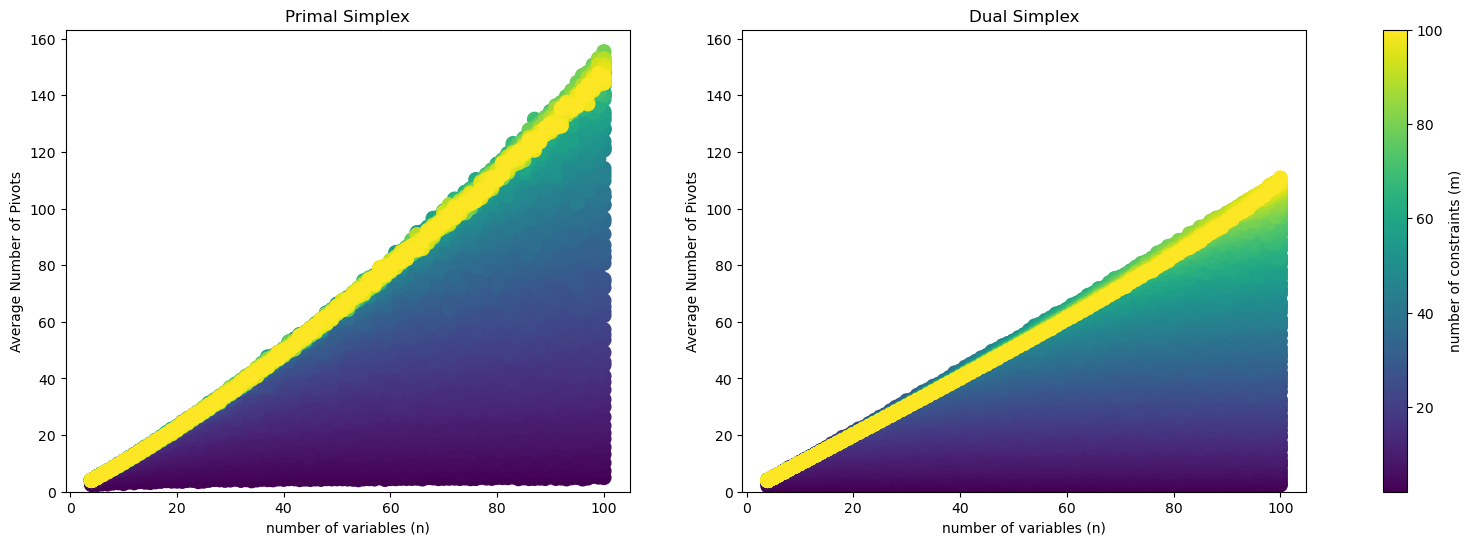

In [36]:
import matplotlib.pyplot as plt

# create two subplots and one color scale

fig, ax = plt.subplots(1, 2, figsize=(20, 6))
ax = ax.flatten()


m_values = sorted(df_two_phase["m"].unique())
color_map = {n: plt.cm.viridis(i / (len(m_values) - 1)) for i, n in enumerate(m_values)}

# the y axis should be the same for both plots, use the same max limit
y_max = max(df_two_phase["average_num_pivots"].max(), df_dual["average_num_pivots"].max())*1.05

for m, group in df_two_phase.groupby("m"):
    group = group.sort_values("average_num_pivots", ascending=True)          # lowest number of pivots drawn last → on top
    ax[0].scatter(
        group["n"],
        group["average_num_pivots"],
        c=[color_map[m] for m in group["m"]],          # manual per-point colors
        s=100,
    )

#add an additional scatter plot for the dual simplex method
for m, group in df_dual.groupby("m"):
    group = group.sort_values("average_num_pivots", ascending=True)          # lowest number of pivots drawn last → on top
    ax[1].scatter(
        group["n"],
        group["average_num_pivots"],
        c=[color_map[m] for m in group["m"]],          # manual per-point colors
        s=100,
    )


# Create a legend for the color map (m values)
# from matplotlib.lines import Line2D
# handles = [
#     Line2D([], [], marker="o", linestyle="", color=color_map[n], label=f"n={n}")
#     for n in n_values
# ]
# plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=4)

# Show a gradient color map for n values
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(m_values), vmax=max(m_values)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label="number of constraints (m)", )



ax[0].set_xlabel("number of variables (n)")
ax[0].set_ylabel("Average Number of Pivots")
ax[0].set_title("Primal Simplex")
ax[0].set_ylim(0, y_max)
ax[1].set_xlabel("number of variables (n)")
ax[1].set_ylabel("Average Number of Pivots")
ax[1].set_title("Dual Simplex")
ax[1].set_ylim(0, y_max)

fig.show()
# save the figure
fig.savefig("pivots_vs_n.png")

In [38]:
two_phase_results = pd.read_csv("simplex_benchmark_results_report_default.csv")
report_table = two_phase_results[["n", "m", "average_num_pivots", "average_time", "average_cost", "average_nonzero_vars",
                        "num_infeasible", "num_unbounded"]].copy()

dual_results = pd.read_csv("highs-ds_benchmark_results_report_default.csv")

report_table["average_time"] = report_table["average_time"] * 1000  # seconds -> ms
report_table = report_table.rename(columns={
    "average_num_pivots": "two-phase pivots",
    "average_time": "two-phase time (ms)",
    "average_cost": "cost",
    "average_nonzero_vars": "nonzero vars",
    "num_infeasible": "infeasible",
    "num_unbounded": "unbounded",
})
# add two columns for number of pivots and time required for dual revised
report_table["dual pivots"] = dual_results["average_num_pivots"]
report_table["dual time (ms)"] = dual_results["average_time"] * 1000  # seconds -> ms

#move dual columns after the original pivots and time columns
cols = report_table.columns.tolist()
cols.insert(cols.index("two-phase time (ms)") + 1, cols.pop(cols.index("dual pivots")))
cols.insert(cols.index("dual pivots") + 1, cols.pop(cols.index("dual time (ms)")))
report_table = report_table[cols]

report_table = report_table.round(3)
report_table

,n,m,two-phase pivots,two-phase time (ms),dual pivots,dual time (ms),cost,nonzero vars,infeasible,unbounded
0,4,2,2.233,3.229,2.067,4.800,601.644,2.0,0,0
1,4,6,4.033,2.446,4.000,4.058,1080.826,4.0,0,0
2,4,10,4.033,2.282,4.000,3.203,995.245,4.0,0,0
3,4,14,4.033,4.961,4.000,5.142,970.090,4.0,0,0
4,10,2,3.100,5.333,2.067,3.449,423.646,2.0,0,0
5,10,6,7.733,6.632,6.733,2.876,1625.470,6.0,0,0
6,10,10,10.533,6.141,10.200,2.969,2555.027,10.0,0,0
7,10,14,10.733,7.443,10.133,2.469,2488.738,10.0,0,0
8,20,2,3.733,4.394,2.167,3.751,332.051,2.0,0,0
9,20,6,10.100,5.899,7.133,2.540,1493.990,6.0,0,0
